<a href="https://colab.research.google.com/github/GilbertOwen/reefscan-id/blob/drive-raw-data/notebooks/02_stage1_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ReefScan-ID: Stage 1 segmentation

Stage 1 of the cascade: segment a diver photo into coral / substrate / other. Run in Google Colab with a T4 GPU runtime.

### Setup: Colab runtime and Google Drive

In [2]:
import os
import torch
from google.colab import drive


drive.mount("/content/drive")

gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none"
print("GPU: {}".format(gpu_name))

base_dir = "/content/drive/MyDrive/ReefScan-ID"
print("Drive folder found: {}".format(os.path.isdir(base_dir)))

Mounted at /content/drive
GPU: NVIDIA A100-SXM4-40GB
Drive folder found: True


### Setup: libraries

In [3]:
!pip install -q datasets
import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
print("datasets version: {}".format(datasets.__version__))

datasets version: 4.8.5


## Section 1: Mask ID check

Question: which class ids appear in the Coralscapes masks, and do they match the 39 classes listed on the dataset card?

Checks: count the pixels of every mask value in the train and validation splits, then compare the values found with the ids on the card. The test split is left out here because it is kept for the final evaluation.

### Load the dataset

In [4]:
raw_dir = base_dir + "/RawData"

import time
from datasets import load_dataset


print("Cache folder exists: {}".format(os.path.isdir(raw_dir)))

start = time.time()
ds = load_dataset("EPFL-ECEO/coralscapes", cache_dir=raw_dir)
load_seconds = time.time() - start
print(ds)

cache_bytes = 0
for root, dirs, files in os.walk(raw_dir):
    for name in files:
        cache_bytes += os.path.getsize(os.path.join(root, name))
print("Cache folder size: {:.2f} GB".format(cache_bytes / 1024 ** 3))
print("Loading took {:.1f} seconds".format(load_seconds))

Cache folder exists: True


README.md:   0%|          | 0.00/13.7k [00:00<?, ?B/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 1517
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 166
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 392
    })
})
Cache folder size: 5.45 GB
Loading took 19.3 seconds


### Optional: copy the cache to the Colab disk

Set `use_local_copy = True` to copy the Drive cache to `/content` and load from there. Used to compare the loading time from Drive with the loading time from a local copy.

In [5]:
import shutil

use_local_copy = False
local_dir = "/content/RawData"

if not use_local_copy:
    print("SKIPPED: local copy not requested")
else:
    start = time.time()
    if not os.path.isdir(local_dir):
        shutil.copytree(raw_dir, local_dir)
    print("Copy took {:.1f} seconds".format(time.time() - start))

    start = time.time()
    ds = load_dataset("EPFL-ECEO/coralscapes", cache_dir=local_dir)
    print("Loading from the local copy took {:.1f} seconds".format(time.time() - start))

SKIPPED: local copy not requested


### Class names from the dataset card

Ids and names copied from the table on the Coralscapes dataset card (read 2026-11-12).

In [6]:
class_names = {
    1: "seagrass",
    2: "trash",
    3: "other coral dead",
    4: "other coral bleached",
    5: "sand",
    6: "other coral alive",
    7: "human",
    8: "transect tools",
    9: "fish",
    10: "algae covered substrate",
    11: "other animal",
    12: "unknown hard substrate",
    13: "background",
    14: "dark",
    15: "transect line",
    16: "massive/meandering bleached",
    17: "massive/meandering alive",
    18: "rubble",
    19: "branching bleached",
    20: "branching dead",
    21: "millepora",
    22: "branching alive",
    23: "massive/meandering dead",
    24: "clam",
    25: "acropora alive",
    26: "sea cucumber",
    27: "turbinaria",
    28: "table acropora alive",
    29: "sponge",
    30: "anemone",
    31: "pocillopora alive",
    32: "table acropora dead",
    33: "meandering bleached",
    34: "stylophora alive",
    35: "sea urchin",
    36: "meandering alive",
    37: "meandering dead",
    38: "crown of thorn",
    39: "dead clam",
}

print("Classes on the card: {}".format(len(class_names)))

Classes on the card: 39


### Count pixels per mask value

In [7]:
import numpy as np

pixel_counts = {}
for split in ["train", "validation"]:
    counts = np.zeros(256, dtype=np.int64)
    masks = ds[split].select_columns(["label"])
    for row in masks:
        mask = np.array(row["label"])
        counts += np.bincount(mask.ravel(), minlength=256)
    pixel_counts[split] = counts
    print("{}: {} masks counted, {} pixels".format(split, masks.num_rows, counts.sum()))

train: 1517 masks counted, 3181379584 pixels
validation: 166 masks counted, 348127232 pixels


### Mask values found against the card

In [8]:
import pandas as pd

train_counts = pixel_counts["train"]
val_counts = pixel_counts["validation"]
found = [int(v) for v in np.nonzero(train_counts + val_counts)[0]]

rows = []
for value in found:
    rows.append({
        "id": value,
        "name": class_names.get(value, "NOT ON THE CARD"),
        "train_pct": 100 * train_counts[value] / train_counts.sum(),
        "val_pct": 100 * val_counts[value] / val_counts.sum(),
    })
table = pd.DataFrame(rows)
print(table.to_string(index=False, float_format="{:.3f}".format))

not_on_card = [v for v in found if v not in class_names]
never_seen = [i for i in class_names if i not in found]
print("Mask values found: {}".format(len(found)))
print("Values found that are not on the card: {}".format(not_on_card))
print("Card ids that never appear in train or validation: {}".format(never_seen))

 id                        name  train_pct  val_pct
  0             NOT ON THE CARD     17.048   13.987
  1                    seagrass      0.761    0.000
  2                       trash      0.046    0.006
  3            other coral dead      0.208    2.013
  4        other coral bleached      0.249    0.184
  5                        sand      6.187   11.658
  6           other coral alive      3.781    3.015
  7                       human      1.112    2.039
  8              transect tools      0.071    0.104
  9                        fish      0.469    0.202
 10     algae covered substrate      5.101    1.634
 11                other animal      0.035    0.003
 12      unknown hard substrate     11.909   14.143
 13                  background     21.618   31.457
 14                        dark      5.009    2.717
 15               transect line      0.263    0.255
 16 massive/meandering bleached      0.092    0.670
 17    massive/meandering alive      8.998    3.834
 18         

**Observation**: All 39 class IDs from the dataset card were found. An additional ID 0 was present, accounting for 17.05% of train pixels and 13.99% of validation pixels, so it is treated as an ignored label (255).

## Section 2: Class mapping

Question: how many pixels fall into each stage 1 group (coral / substrate / other) once the 39 Coralscapes classes are mapped to 3?

Checks: build an array that maps every mask value to a group, list the classes in each group, then compute the pixel share of each group on the train and validation splits from the counts of Section 1.

### Build the mapping array

In [9]:
coral_ids = [3, 4, 6, 16, 17, 19, 20, 21, 22, 23, 25, 27, 28, 31, 32, 33, 34, 36, 37]
substrate_ids = [5, 10, 12, 18]
group_names = {0: "coral", 1: "substrate", 2: "other"}
ignore_id = 255

# Values that are not on the card stay at the ignore id
mapping = np.full(256, ignore_id, dtype=np.uint8)
for value in class_names:
    mapping[value] = 2
mapping[coral_ids] = 0
mapping[substrate_ids] = 1

for group_id, group_name in group_names.items():
    names = [class_names[v] for v in class_names if mapping[v] == group_id]
    print("{} ({} ids): {}".format(group_name, len(names), names))
print("Mask value 0 maps to: {}".format(mapping[0]))

coral (19 ids): ['other coral dead', 'other coral bleached', 'other coral alive', 'massive/meandering bleached', 'massive/meandering alive', 'branching bleached', 'branching dead', 'millepora', 'branching alive', 'massive/meandering dead', 'acropora alive', 'turbinaria', 'table acropora alive', 'pocillopora alive', 'table acropora dead', 'meandering bleached', 'stylophora alive', 'meandering alive', 'meandering dead']
substrate (4 ids): ['sand', 'algae covered substrate', 'unknown hard substrate', 'rubble']
other (16 ids): ['seagrass', 'trash', 'human', 'transect tools', 'fish', 'other animal', 'background', 'dark', 'transect line', 'clam', 'sea cucumber', 'sponge', 'anemone', 'sea urchin', 'crown of thorn', 'dead clam']
Mask value 0 maps to: 255


### Pixel share per group

In [10]:
for split in ["train", "validation"]:
    counts = pixel_counts[split]
    total = counts.sum()
    for group_id, group_name in group_names.items():
        share = 100 * counts[mapping == group_id].sum() / total
        print("{} {}: {:.2f}% of all pixels".format(split, group_name, share))
    ignored = 100 * counts[mapping == ignore_id].sum() / total
    print("{} ignored: {:.2f}% of all pixels".format(split, ignored))

train coral: 25.60% of all pixels
train substrate: 27.53% of all pixels
train other: 29.81% of all pixels
train ignored: 17.05% of all pixels
validation coral: 19.57% of all pixels
validation substrate: 29.36% of all pixels
validation other: 37.08% of all pixels
validation ignored: 13.99% of all pixels


**Observation**: The 39 classes were successfully grouped into coral, substrate, and other. Their labelled training pixel shares were 30.87%, 33.19%, and 35.94%, respectively, indicating relatively balanced classes.

## Section 3: Crop dataset

Question: does the training data pipeline give random 512 by 512 crops whose images and masks line up, with the masks already mapped to the three groups?

Checks: build a dataset that cuts a random crop from each photo and applies the class mapping to the mask, read one batch from the train and validation loaders, print the shapes, data types and label values, time ten train batches, and draw one crop next to its mask.

### Library versions

In [11]:
import matplotlib

print("torch version: {}".format(torch.__version__))
print("numpy version: {}".format(np.__version__))
print("matplotlib version: {}".format(matplotlib.__version__))

torch version: 2.14.1+cu130
numpy version: 2.4.6
matplotlib version: 3.10.0


### Crop dataset class

In [12]:
import random
from torch.utils.data import Dataset

crop_size = 512


class CropDataset(Dataset):
    def __init__(self, split, crop_size, flip):
        self.split = split
        self.crop_size = crop_size
        self.flip = flip

    def __len__(self):
        return self.split.num_rows

    def __getitem__(self, index):
        row = self.split[index]
        image = np.array(row["image"])
        mask = mapping[np.array(row["label"])]

        # Same random window for the image and the mask
        top = random.randint(0, image.shape[0] - self.crop_size)
        left = random.randint(0, image.shape[1] - self.crop_size)
        image = image[top:top + self.crop_size, left:left + self.crop_size]
        mask = mask[top:top + self.crop_size, left:left + self.crop_size]

        if self.flip and random.random() < 0.5:
            image = image[:, ::-1]
            mask = mask[:, ::-1]

        image = torch.from_numpy(image.copy()).permute(2, 0, 1).float() / 255
        mask = torch.from_numpy(mask.copy()).long()
        return image, mask


print("Crop size: {}".format(crop_size))

Crop size: 512


### Data loaders

In [13]:
from torch.utils.data import DataLoader

batch_size = 8
num_workers = 2

train_data = CropDataset(ds["train"], crop_size, flip=True)
val_data = CropDataset(ds["validation"], crop_size, flip=False)

train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=num_workers)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=num_workers)

print("Train crops per epoch: {}, batches: {}".format(len(train_data), len(train_loader)))
print("Validation crops per epoch: {}, batches: {}".format(len(val_data), len(val_loader)))

Train crops per epoch: 1517, batches: 190
Validation crops per epoch: 166, batches: 21


### One batch check

In [14]:
for name, loader in [("train", train_loader), ("validation", val_loader)]:
    images, masks = next(iter(loader))
    print("{} images: shape {}, dtype {}, min {:.3f}, max {:.3f}".format(
        name, tuple(images.shape), images.dtype, images.min().item(), images.max().item()))
    print("{} masks: shape {}, dtype {}, values {}".format(
        name, tuple(masks.shape), masks.dtype, torch.unique(masks).tolist()))

start = time.time()
steps = 0
for images, masks in train_loader:
    steps += 1
    if steps == 10:
        break
print("Reading {} train batches took {:.1f} seconds".format(steps, time.time() - start))

train images: shape (8, 3, 512, 512), dtype torch.float32, min 0.000, max 1.000
train masks: shape (8, 512, 512), dtype torch.int64, values [0, 1, 2, 255]
validation images: shape (8, 3, 512, 512), dtype torch.float32, min 0.000, max 1.000
validation masks: shape (8, 512, 512), dtype torch.int64, values [0, 1, 2, 255]
Reading 10 train batches took 6.9 seconds


### Crop and mask overlay

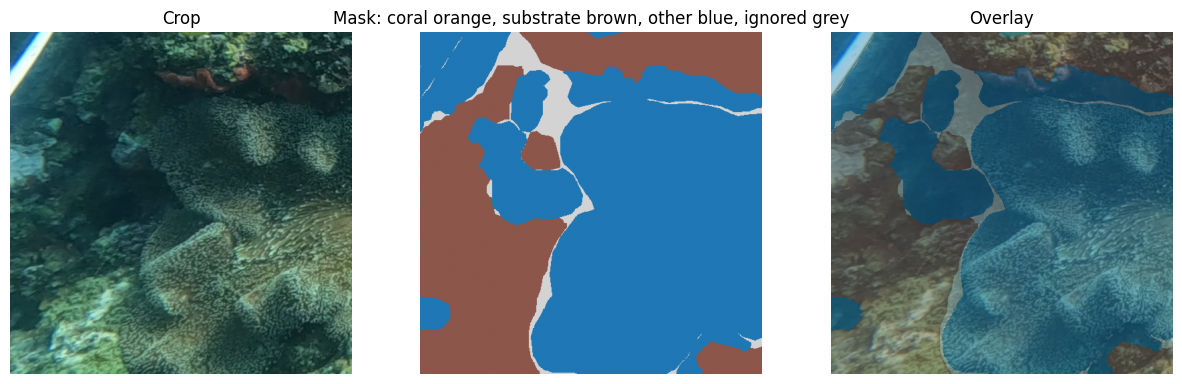

In [15]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

image, mask = train_data[0]
picture = image.permute(1, 2, 0).numpy()
shown = mask.numpy().copy()
shown[shown == ignore_id] = 3
colours = ListedColormap(["tab:orange", "tab:brown", "tab:blue", "lightgrey"])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(picture)
axes[0].set_title("Crop")
axes[1].imshow(shown, cmap=colours, vmin=0, vmax=3)
axes[1].set_title("Mask: coral orange, substrate brown, other blue, ignored grey")
axes[2].imshow(picture)
axes[2].imshow(shown, cmap=colours, vmin=0, vmax=3, alpha=0.4)
axes[2].set_title("Overlay")
for ax in axes:
    ax.axis("off")
plt.show()

**Observation**: Both train and validation loaders produced correctly shaped 512×512 image and mask crops with the expected labels. The overlay also provides a visual check of image-mask alignment.

## Section 4: Model

Question: does SegFormer-B0 load with three output classes and run on one batch of crops, and how long does one training step take on the Colab GPU?

Checks: load the model from the pretrained weights and count its parameters, run one forward pass on a train batch and print the output shapes, then time 30 training steps with data loading and the model step measured separately.

### Load SegFormer-B0

In [16]:
import transformers
from transformers import SegformerForSemanticSegmentation

weights_name = "nvidia/mit-b0"
device = "cuda" if torch.cuda.is_available() else "cpu"

model = SegformerForSemanticSegmentation.from_pretrained(
    weights_name,
    num_labels=len(group_names),
    id2label=group_names,
    label2id={name: group_id for group_id, name in group_names.items()},
    ignore_mismatched_sizes=True,
)
model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("transformers version: {}".format(transformers.__version__))
print("Weights: {}".format(weights_name))
print("Device: {}".format(device))
print("Parameters: {} total, {} trainable".format(total_params, trainable_params))

config.json:   0%|          | 0.00/70.0k [00:00<?, ?B/s]

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `1000`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 14.4MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b0
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.bias                                         | UNEXPECTED | 
classifier.weight                                       | UNEXPECTED | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.linear_fuse.weight                          | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.bias                             

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.3MB            

model.safetensors: downloading bytes:           |  0.00B            

transformers version: 5.22.1
Weights: nvidia/mit-b0
Device: cuda
Parameters: 3714915 total, 3714915 trainable


### One forward pass

In [17]:
image_mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
image_std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

images, masks = next(iter(train_loader))
pixel_values = (images.to(device) - image_mean) / image_std

model.eval()
with torch.no_grad():
    logits = model(pixel_values=pixel_values).logits
upsampled = torch.nn.functional.interpolate(logits, size=masks.shape[-2:], mode="bilinear", align_corners=False)

print("Input shape: {}".format(tuple(pixel_values.shape)))
print("Logits shape: {}".format(tuple(logits.shape)))
print("Upsampled logits shape: {}".format(tuple(upsampled.shape)))

Input shape: (8, 3, 512, 512)
Logits shape: (8, 3, 128, 128)
Upsampled logits shape: (8, 3, 512, 512)


### Step timing

In [18]:
import copy

# Loss and optimiser here are placeholders for timing only
timing_steps = 30
timing_model = copy.deepcopy(model)
timing_model.train()
timing_optimizer = torch.optim.AdamW(timing_model.parameters(), lr=1e-5)

data_seconds = 0.0
step_seconds = 0.0
batches = iter(train_loader)
for step in range(timing_steps):
    start = time.time()
    images, masks = next(batches)
    data_seconds += time.time() - start

    start = time.time()
    pixel_values = (images.to(device) - image_mean) / image_std
    loss = timing_model(pixel_values=pixel_values, labels=masks.to(device)).loss
    timing_optimizer.zero_grad()
    loss.backward()
    timing_optimizer.step()
    if device == "cuda":
        torch.cuda.synchronize()
    step_seconds += time.time() - start

print("Steps timed: {}, batch size: {}".format(timing_steps, batch_size))
print("Data loading: {:.2f} seconds per step".format(data_seconds / timing_steps))
print("Model step: {:.2f} seconds per step".format(step_seconds / timing_steps))
print("Total: {:.2f} seconds per step".format((data_seconds + step_seconds) / timing_steps))

Steps timed: 30, batch size: 8
Data loading: 0.32 seconds per step
Model step: 0.10 seconds per step
Total: 0.42 seconds per step


**Observation**: SegFormer-B0 loaded successfully with 3.71 million trainable parameters. It produced the expected three-class output, with an average training step time of approximately 0.42 seconds.

## Section 5: Training

Question: how do the training loss, the validation mIoU and the coral IoU of SegFormer-B0 change over the epochs, and where does the data loading time go?

Checks: time the parts of loading one train photo, compute the class weights from the train pixel counts, build the validation set from whole photos resized to 512 by 1024, score the untrained model once, then train with a checkpoint after every epoch and plot the curves. Only the train and validation splits are used.

### Data loading profile

In [19]:
import io
from PIL import Image
from datasets import Image as HFImage

profile_items = 20
raw_train = ds["train"].cast_column("image", HFImage(decode=False)).cast_column("label", HFImage(decode=False))

read_seconds = 0.0
decode_seconds = 0.0
crop_seconds = 0.0
for index in range(profile_items):
    start = time.time()
    row = raw_train[index]
    read_seconds += time.time() - start

    start = time.time()
    image = np.array(Image.open(io.BytesIO(row["image"]["bytes"])))
    label = np.array(Image.open(io.BytesIO(row["label"]["bytes"])))
    decode_seconds += time.time() - start

    start = time.time()
    mask = mapping[label]
    image = image[:crop_size, :crop_size]
    mask = mask[:crop_size, :crop_size]
    image = torch.from_numpy(image.copy()).permute(2, 0, 1).float() / 255
    mask = torch.from_numpy(mask.copy()).long()
    crop_seconds += time.time() - start

print("CPU count: {}".format(os.cpu_count()))
print("Photos timed: {}".format(profile_items))
print("Read the row from the cache: {:.3f} seconds per photo".format(read_seconds / profile_items))
print("Decode image and mask: {:.3f} seconds per photo".format(decode_seconds / profile_items))
print("Mapping, crop and tensor: {:.3f} seconds per photo".format(crop_seconds / profile_items))

CPU count: 12
Photos timed: 20
Read the row from the cache: 0.003 seconds per photo
Decode image and mask: 0.088 seconds per photo
Mapping, crop and tensor: 0.006 seconds per photo


### Class weights and loss

In [20]:
train_counts = pixel_counts["train"]
group_pixels = np.array([train_counts[mapping == group_id].sum() for group_id in group_names])
group_share = group_pixels / group_pixels.sum()
class_weights = 1 / group_share
class_weights = class_weights / class_weights.mean()

for group_id, group_name in group_names.items():
    print("{}: {:.2f}% of labelled train pixels, weight {:.3f}".format(
        group_name, 100 * group_share[group_id], class_weights[group_id]))

weight_tensor = torch.tensor(class_weights, dtype=torch.float32, device=device)


def segmentation_loss(logits, masks):
    upsampled = torch.nn.functional.interpolate(logits, size=masks.shape[-2:], mode="bilinear", align_corners=False)
    return torch.nn.functional.cross_entropy(upsampled, masks, weight=weight_tensor, ignore_index=ignore_id)

coral: 30.87% of labelled train pixels, weight 1.076
substrate: 33.19% of labelled train pixels, weight 1.000
other: 35.94% of labelled train pixels, weight 0.924


### Validation data

In [21]:
val_height = 512
val_width = 1024
val_batch_size = 4


class ResizeDataset(Dataset):
    def __init__(self, split, height, width):
        self.split = split
        self.height = height
        self.width = width

    def __len__(self):
        return self.split.num_rows

    def __getitem__(self, index):
        row = self.split[index]
        image = row["image"].resize((self.width, self.height), Image.BILINEAR)
        label = row["label"].resize((self.width, self.height), Image.NEAREST)
        image = torch.from_numpy(np.array(image)).permute(2, 0, 1).float() / 255
        mask = torch.from_numpy(mapping[np.array(label)]).long()
        return image, mask


eval_data = ResizeDataset(ds["validation"], val_height, val_width)
eval_loader = DataLoader(eval_data, batch_size=val_batch_size, shuffle=False, num_workers=num_workers)

images, masks = next(iter(eval_loader))
print("Validation photos: {}, batches: {}".format(len(eval_data), len(eval_loader)))
print("Images: shape {}, dtype {}".format(tuple(images.shape), images.dtype))
print("Masks: shape {}, dtype {}, values {}".format(tuple(masks.shape), masks.dtype, torch.unique(masks).tolist()))

Validation photos: 166, batches: 42
Images: shape (4, 3, 512, 1024), dtype torch.float32
Masks: shape (4, 512, 1024), dtype torch.int64, values [0, 1, 2, 255]


### Validation metrics

In [22]:
group_count = len(group_names)


def evaluate(model, loader):
    confusion = torch.zeros(group_count, group_count, dtype=torch.int64, device=device)
    model.eval()
    with torch.no_grad():
        for images, masks in loader:
            pixel_values = (images.to(device) - image_mean) / image_std
            masks = masks.to(device)
            logits = model(pixel_values=pixel_values).logits
            upsampled = torch.nn.functional.interpolate(logits, size=masks.shape[-2:], mode="bilinear", align_corners=False)
            predicted = upsampled.argmax(dim=1)

            # Pixels with the ignore id are left out
            keep = masks != ignore_id
            pairs = masks[keep] * group_count + predicted[keep]
            confusion += torch.bincount(pairs, minlength=group_count ** 2).reshape(group_count, group_count)

    intersection = confusion.diag().float()
    union = confusion.sum(dim=0).float() + confusion.sum(dim=1).float() - intersection
    return (intersection / union).cpu().numpy()


start = time.time()
iou = evaluate(model, eval_loader)
print("Model before training")
for group_id, group_name in group_names.items():
    print("{} IoU: {:.4f}".format(group_name, iou[group_id]))
print("mIoU: {:.4f}".format(iou.mean()))
print("One validation pass took {:.1f} seconds".format(time.time() - start))

Model before training
coral IoU: 0.1789
substrate IoU: 0.1458
other IoU: 0.2554
mIoU: 0.1933
One validation pass took 9.8 seconds


### Optimiser and schedule

In [23]:
epochs = 50
learning_rate = 6e-5
weight_decay = 0.01
total_steps = epochs * len(train_loader)

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda step: max(0.0, 1 - step / total_steps))

print("Epochs: {}, steps per epoch: {}, total steps: {}".format(epochs, len(train_loader), total_steps))
print("Learning rate: {}, weight decay: {}, batch size: {}".format(learning_rate, weight_decay, batch_size))

Epochs: 50, steps per epoch: 190, total steps: 9500
Learning rate: 6e-05, weight decay: 0.01, batch size: 8


### Checkpoint and resume

In [24]:
resume = True
checkpoint_dir = base_dir + "/Checkpoints/stage1_segformer_b0"
os.makedirs(checkpoint_dir, exist_ok=True)
last_path = checkpoint_dir + "/last.pt"
best_path = checkpoint_dir + "/best.pt"

start_epoch = 0
global_step = 0
best_miou = 0.0
history = []

if resume and os.path.isfile(last_path):
    checkpoint = torch.load(last_path, map_location=device)
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scheduler.load_state_dict(checkpoint["scheduler"])
    start_epoch = checkpoint["epoch"]
    global_step = checkpoint["global_step"]
    best_miou = checkpoint["best_miou"]
    history = checkpoint["history"]
    print("Resumed after epoch {}, step {}, best mIoU {:.4f}".format(start_epoch, global_step, best_miou))
else:
    print("No checkpoint loaded: training starts from the pretrained weights")

print("Checkpoint folder: {}".format(checkpoint_dir))

Resumed after epoch 3, step 570, best mIoU 0.6129
Checkpoint folder: /content/drive/MyDrive/ReefScan-ID/Checkpoints/stage1_segformer_b0


### Training loop

In [25]:
for epoch in range(start_epoch, epochs):
    epoch_start = time.time()
    model.train()
    loss_sum = 0.0
    for images, masks in train_loader:
        pixel_values = (images.to(device) - image_mean) / image_std
        logits = model(pixel_values=pixel_values).logits
        loss = segmentation_loss(logits, masks.to(device))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        global_step += 1
        loss_sum += loss.item()

    iou = evaluate(model, eval_loader)
    miou = float(iou.mean())
    history.append({
        "epoch": epoch + 1,
        "train_loss": loss_sum / len(train_loader),
        "miou": miou,
        "coral_iou": float(iou[0]),
        "substrate_iou": float(iou[1]),
        "other_iou": float(iou[2]),
        "seconds": time.time() - epoch_start,
    })

    is_best = miou > best_miou
    if is_best:
        best_miou = miou

    state = {
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "epoch": epoch + 1,
        "global_step": global_step,
        "best_miou": best_miou,
        "history": history,
    }
    torch.save(state, last_path)
    if is_best:
        torch.save(state, best_path)

    record = history[-1]
    print("Epoch {}: loss {:.4f}, mIoU {:.4f}, coral {:.4f}, substrate {:.4f}, other {:.4f}, {:.0f} seconds, best saved: {}".format(
        record["epoch"], record["train_loss"], record["miou"], record["coral_iou"],
        record["substrate_iou"], record["other_iou"], record["seconds"], is_best))

print("Epochs done: {}, best validation mIoU: {:.4f}".format(len(history), best_miou))

Epoch 4: loss 0.4596, mIoU 0.6509, coral 0.5799, substrate 0.6280, other 0.7449, 87 seconds, best saved: True
Epoch 5: loss 0.4348, mIoU 0.6492, coral 0.5860, substrate 0.6308, other 0.7309, 86 seconds, best saved: False
Epoch 6: loss 0.4284, mIoU 0.6533, coral 0.5756, substrate 0.6274, other 0.7567, 86 seconds, best saved: True
Epoch 7: loss 0.4197, mIoU 0.6393, coral 0.5808, substrate 0.6271, other 0.7099, 87 seconds, best saved: False
Epoch 8: loss 0.4022, mIoU 0.6264, coral 0.5772, substrate 0.6218, other 0.6802, 86 seconds, best saved: False
Epoch 9: loss 0.3895, mIoU 0.6445, coral 0.5805, substrate 0.6344, other 0.7187, 86 seconds, best saved: False
Epoch 10: loss 0.3835, mIoU 0.6570, coral 0.5870, substrate 0.6543, other 0.7297, 86 seconds, best saved: True
Epoch 11: loss 0.3833, mIoU 0.6430, coral 0.5754, substrate 0.6316, other 0.7220, 86 seconds, best saved: False
Epoch 12: loss 0.3675, mIoU 0.6528, coral 0.6003, substrate 0.6467, other 0.7115, 86 seconds, best saved: False
E

### Training curves

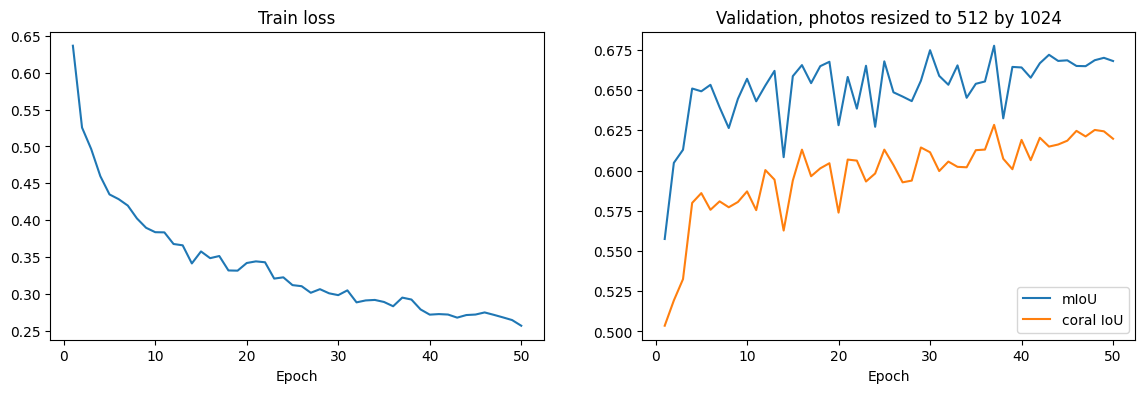

Best epoch: 37, mIoU 0.6775, coral IoU 0.6284


In [26]:
epoch_numbers = [record["epoch"] for record in history]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(epoch_numbers, [record["train_loss"] for record in history])
axes[0].set_title("Train loss")
axes[0].set_xlabel("Epoch")
axes[1].plot(epoch_numbers, [record["miou"] for record in history], label="mIoU")
axes[1].plot(epoch_numbers, [record["coral_iou"] for record in history], label="coral IoU")
axes[1].set_title("Validation, photos resized to {} by {}".format(val_height, val_width))
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.show()

best_record = max(history, key=lambda record: record["miou"])
print("Best epoch: {}, mIoU {:.4f}, coral IoU {:.4f}".format(
    best_record["epoch"], best_record["miou"], best_record["coral_iou"]))

**Observation**: Observation: Training completed 50 epochs, achieving the best validation mIoU of 0.6775 and coral IoU of 0.6284 at epoch 37. Image and mask decoding was the main data-loading bottleneck.